In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


/home/lihaoxing/tmp/ipykernel_20206/1039439376.py:48: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_20206/1039439376.py:297: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


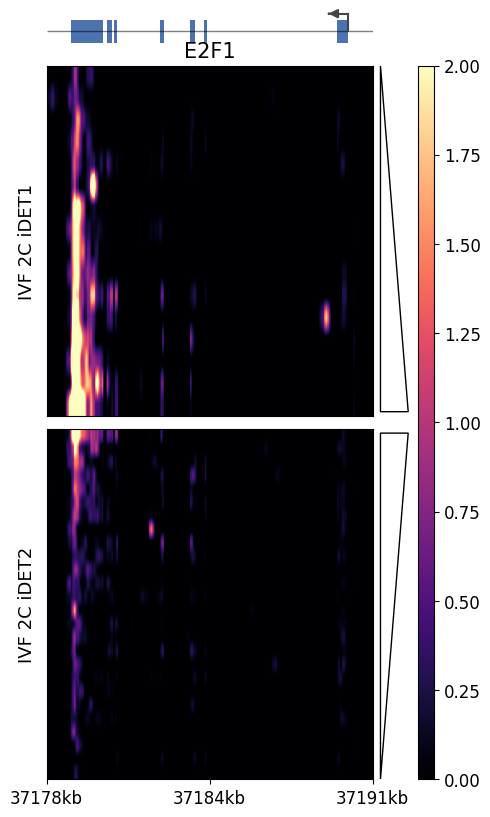

In [65]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# STYLE
# =========================

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",        # 透明内部
        edgecolor="black",       # 黑色边框
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=2)
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 2C iDET1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=2)
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 2C iDET2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('E2F1_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "E2F1"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDET1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDET2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_20206/3290935276.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_20206/3290935276.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


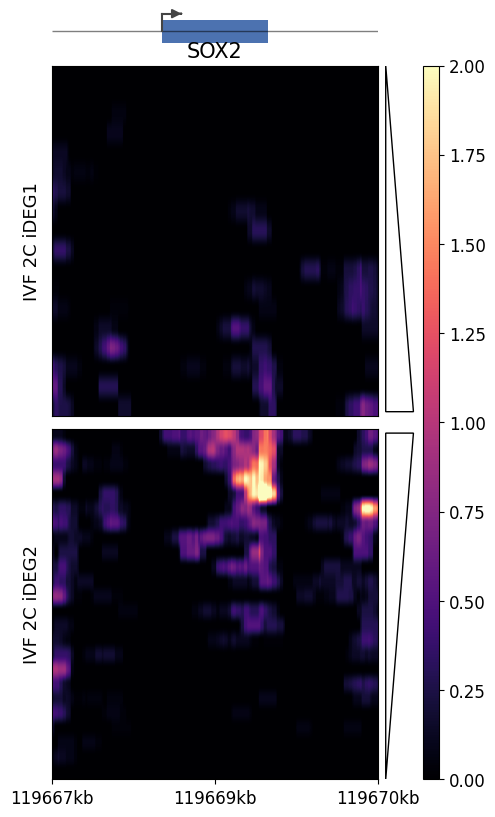

In [66]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=2)
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 2C iDEG1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=2)
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 2C iDEG2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('SOX2_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "SOX2"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDEG1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDEG2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_3126659/3061441793.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_3126659/3061441793.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


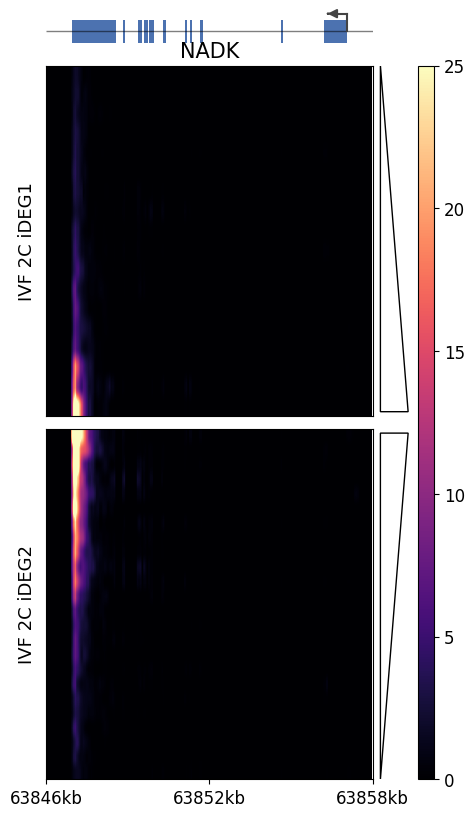

In [5]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=25)#
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 2C iDEG1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=25)#
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 2C iDEG2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('NADK_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "NADK"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDEG1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDEG2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_3126659/1691425463.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_3126659/1691425463.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


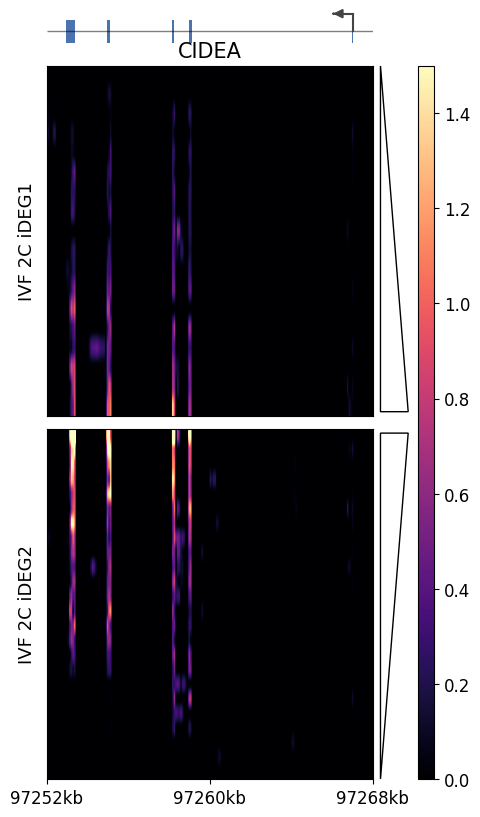

In [9]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=1.5)#
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 2C iDEG1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=1.5)#
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 2C iDEG2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('CIDEA_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "CIDEA"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDEG1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_2C_iDEG2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_20206/4044703231.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_20206/4044703231.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


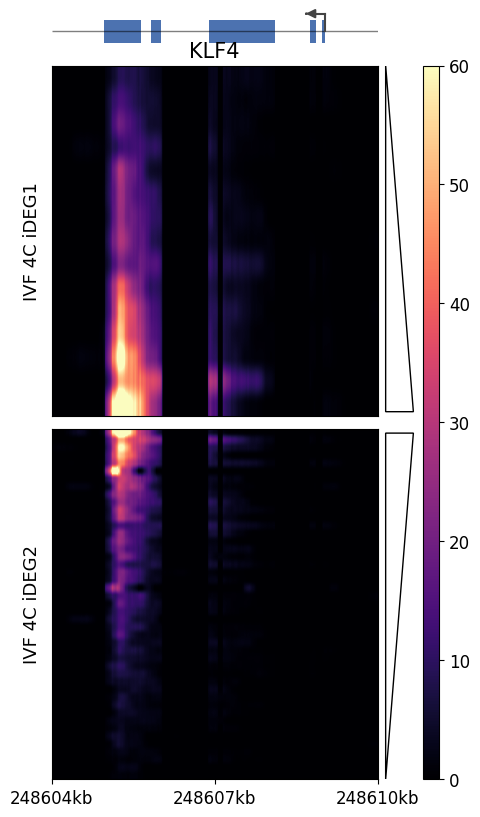

In [67]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=60)
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 4C iDEG1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=60)
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 4C iDEG2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('KLF4_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "KLF4"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDEG1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDEG2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_3126659/34503737.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_3126659/34503737.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


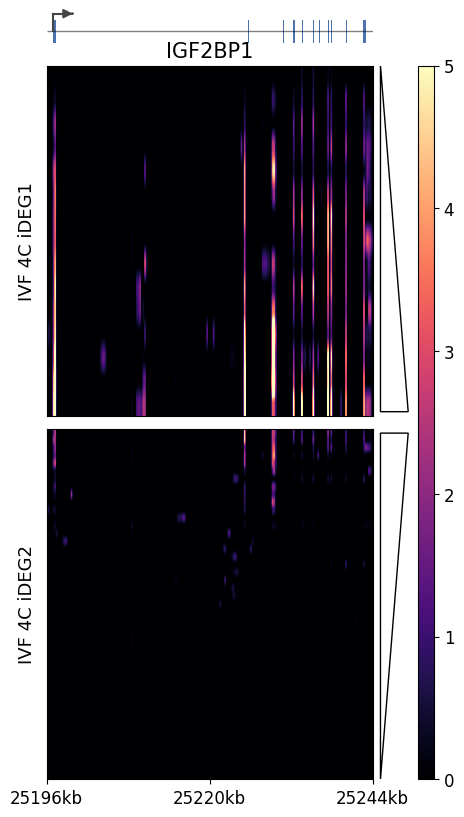

In [16]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=5)
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 4C iDEG1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=5)
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 4C iDEG2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('IGF2BP1_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "IGF2BP1"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDEG1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDEG2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_3126659/33108406.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_3126659/33108406.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


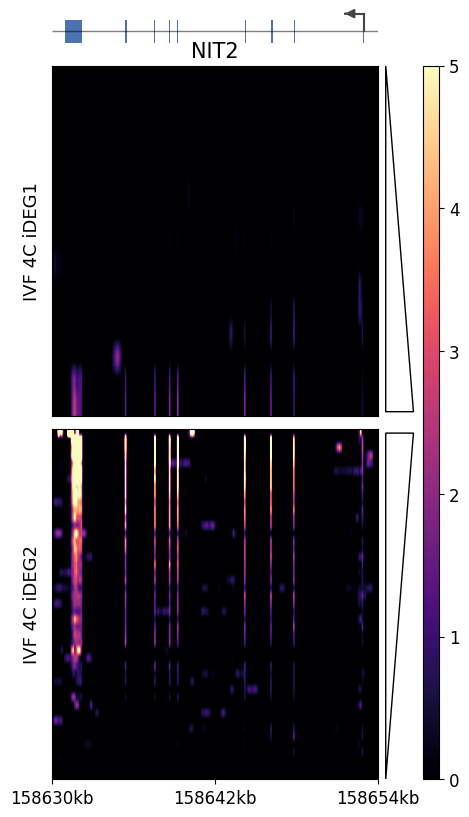

In [17]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=5)
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 4C iDEG1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=5)
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 4C iDEG2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('NIT2_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "NIT2"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDEG1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDEG2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()

/home/lihaoxing/tmp/ipykernel_20206/1123464347.py:47: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
/home/lihaoxing/tmp/ipykernel_20206/1123464347.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


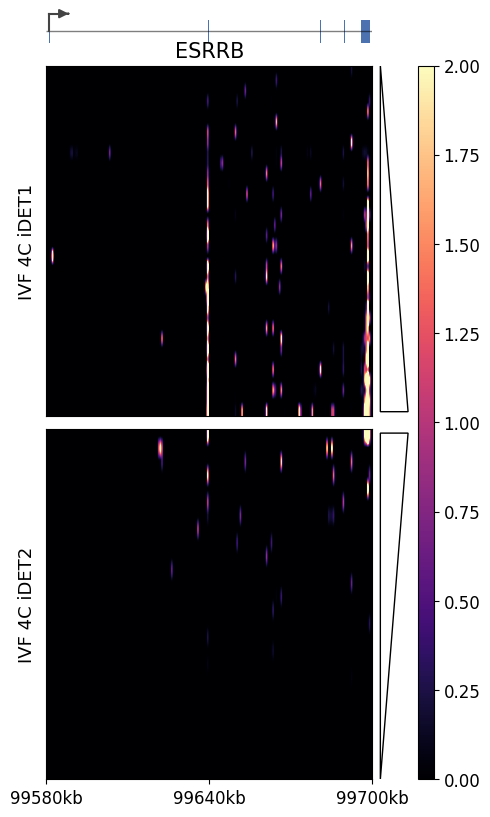

In [68]:
import os
import glob
import pyBigWig
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from matplotlib.patches import Polygon


# =========================
# STYLE
# =========================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

mpl.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})


# =========================
# chrom normalize
# =========================
def normalize_chrom(chrom, bw_chroms):
    chrom = str(chrom)
    if chrom in bw_chroms:
        return chrom
    if "chr" + chrom in bw_chroms:
        return "chr" + chrom
    if chrom.startswith("chr") and chrom[3:] in bw_chroms:
        return chrom[3:]
    return None


# =========================
# gene model ±1kb
# =========================
def get_gene_model(gtf_file, gene_name, flank=1000):

    df = pd.read_csv(gtf_file, sep="\t", comment="#", header=None)
    df.columns = [
        "chrom", "source", "feature", "start", "end",
        "score", "strand", "frame", "attribute"
    ]

    gene_df = df[df["attribute"].str.contains(f'gene_name "{gene_name}"')]
    exon_df = gene_df[gene_df["feature"] == "exon"]

    chrom = str(exon_df.iloc[0]["chrom"])
    strand = exon_df.iloc[0]["strand"]

    gstart = exon_df["start"].min()
    gend = exon_df["end"].max()

    win_start = max(0, gstart - flank)
    win_end = gend + flank

    exons = exon_df[["start", "end"]].values.tolist()

    # TSS
    tss = gstart if strand == "+" else gend

    return chrom, win_start, win_end, strand, exons, gstart, gend, tss


# =========================
# bigWig
# =========================
def extract_signal(bw_file, chrom, start, end):
    bw = pyBigWig.open(bw_file)

    chrom = normalize_chrom(chrom, bw.chroms().keys())
    if chrom is None:
        bw.close()
        return np.zeros(end - start)

    v = bw.values(chrom, int(start), int(end), numpy=True)
    bw.close()

    return np.nan_to_num(v, nan=0.0)


def resize_vector(vec, n_bins=200):
    if len(vec) == 0:
        return np.zeros(n_bins)

    return np.interp(
        np.linspace(0, len(vec) - 1, n_bins),
        np.arange(len(vec)),
        vec
    )


def build_matrix(bw_files, region, n_bins=200):
    chrom, start, end = region

    mat = []
    for bw in bw_files:
        v = extract_signal(bw, chrom, start, end)
        v = resize_vector(v, n_bins)
        mat.append(v)

    return np.array(mat)


# =========================
# gene track + L-shaped TSS
# =========================
def plot_gene(ax, gstart, gend, strand, exons,
              win_start, win_end, n_bins, tss):

    def to_bin(p):
        return (p - win_start) / (win_end - win_start) * n_bins

    # baseline
    ax.hlines(0.5, 0, n_bins, lw=1, color="black", alpha=0.5)

    # exons
    for s, e in exons:
        ax.add_patch(
            plt.Rectangle(
                (to_bin(s), 0.42),
                to_bin(e) - to_bin(s),
                0.16,
                facecolor="#4C72B0",
                edgecolor="none"
            )
        )

    # =========================
    # L-shaped TSS arrow
    # =========================
    tss_x = to_bin(tss)

    y_base = 0.5
    y_top = 0.62

    h = n_bins * 0.05  # stable scale

    ax.plot([tss_x, tss_x], [y_base, y_top], color="#444444", lw=1.5)

    if strand == "+":
        ax.plot([tss_x, tss_x + h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x + h + 2, y_top),
            xytext=(tss_x + h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )
    else:
        ax.plot([tss_x, tss_x - h], [y_top, y_top], color="#444444", lw=1.5)
        ax.annotate(
            "",
            xy=(tss_x - h - 2, y_top),
            xytext=(tss_x - h, y_top),
            arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444444")
        )

    ax.set_xlim(0, n_bins)
    ax.set_ylim(0.35, 0.65)
    ax.axis("off")


# =========================
# sorting
# =========================
def sort_matrix(mat, mode):
    score = mat.mean(axis=1)
    idx = np.argsort(score)
    if mode == "desc":
        idx = idx[::-1]
    return mat[idx]


# =========================
# direction panel
# =========================
def plot_direction_panel(ax, n_rows,
                          top_frac=1.0,
                          mid_frac=0.5,
                          bottom_frac=0.0,
                          gap_frac=0.015,   # ⭐ 控制上下间隙
                          x_left=0.05,
                          x_right=0.9):

    ax.set_xlim(0, 1)
    ax.set_ylim(0, n_rows)
    ax.axis("off")

    # =========================
    # 基础位置
    # =========================
    top = n_rows * top_frac
    mid = n_rows * mid_frac
    bottom = n_rows * bottom_frac

    # ⭐ gap（关键）
    gap = n_rows * gap_frac

    mid_up = mid + gap
    mid_down = mid - gap

    # =========================
    # 上三角（底边上移）
    # =========================
    up_triangle = Polygon(
        [
            [x_left, top],
            [x_left, mid_up],
            [x_right, mid_up]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    # =========================
    # 下三角（顶边下移）
    # =========================
    down_triangle = Polygon(
        [
            [x_left, mid_down],
            [x_right, mid_down],
            [x_left, bottom]
        ],
        closed=True,
        facecolor="none",
        edgecolor="black"
    )

    ax.add_patch(up_triangle)
    ax.add_patch(down_triangle)

# =========================
# MAIN FIGURE
# =========================
def plot_two_panels(mat1, mat2, gene_model, title=""):

    chrom, win_start, win_end, strand, exons, gstart, gend, tss = gene_model
    n_bins = mat1.shape[1]

    fig = plt.figure(figsize=(5, 10))

    gs = gridspec.GridSpec(
        3, 3,
        height_ratios=[1, 8, 8],
        width_ratios=[20, 2, 1],
        hspace=0.05,
        wspace=0.05
    )

    # gene
    ax_gene = fig.add_subplot(gs[0, 0])
    plot_gene(ax_gene, gstart, gend, strand,
              exons, win_start, win_end, n_bins, tss)

    # heatmap 1
    ax1 = fig.add_subplot(gs[1, 0])
    im1 = ax1.imshow(mat1, aspect="auto", cmap="magma", vmin=0, vmax=2)
    ax1.set_yticks([])
    ax1.set_xticks([])
    ax1.set_ylabel("IVF 4C iDET1", rotation=90)

    # heatmap 2
    ax2 = fig.add_subplot(gs[2, 0])
    im2 = ax2.imshow(mat2, aspect="auto", cmap="magma", vmin=0, vmax=2)
    ax2.set_yticks([])
    ax2.set_ylabel("IVF 4C iDET2", rotation=90)

    # x-axis
    xt = np.linspace(0, n_bins, 3)
    genome = np.linspace(win_start, win_end, 3).astype(int)
    ax2.set_xticks(xt)
    ax2.set_xticklabels([f"{x/1e3:.0f}kb" for x in genome])

    ax1.set_xlim(0, n_bins)
    ax2.set_xlim(0, n_bins)

    # direction panel
    ax_dir = fig.add_subplot(gs[1:, 1])
    plot_direction_panel(ax_dir, mat1.shape[0])
    
    # colorbar
    cax = fig.add_subplot(gs[1:, 2])
    plt.colorbar(im2, cax=cax)

    ax1.set_title(title)

    plt.tight_layout()
    plt.savefig('ESRRB_bw.svg', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()


# =========================
# MAIN
# =========================
def main():

    gtf = "/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/Sus_scrofa.Sscrofa11.1.115.representative.chr.gtf"
    gene = "ESRRB"

    iDET1_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDET1/*.CPM.bw"))
    iDET2_bw = sorted(glob.glob(
        "/home/lihaoxing/scRNAseq/03align_out_all_mapped/IVF_4C_iDET2/*.CPM.bw"))

    gene_model = get_gene_model(gtf, gene, flank=1000)

    chrom, start, end, strand, exons, gstart, gend, tss = gene_model

    mat1 = build_matrix(iDET1_bw, (chrom, start, end), n_bins=200)
    mat2 = build_matrix(iDET2_bw, (chrom, start, end), n_bins=200)

    mat1 = sort_matrix(mat1, "asc")
    mat2 = sort_matrix(mat2, "desc")

    plot_two_panels(mat1, mat2, gene_model, title=gene)


if __name__ == "__main__":
    main()